# Learning Curve

**Family:** Machine learning &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Machine learning:* Evaluate and explain fitted models: classification performance, calibration, learning curves, residuals, feature importance and feature effects.

## Design purpose

Plots training and cross-validated performance against the number of training examples. The gap and the trend tell you whether a model is underfitting, overfitting, or would benefit from more data.

## When to use

- Decide whether collecting more data is likely to improve a model
- Diagnose overfitting (large train–validation gap) or underfitting (both scores low)
- Compare how quickly candidate models learn from limited data

## Avoid when

- The dataset is tiny (cross-validation scores will be too noisy to compare)
- You want to compare models at one fixed data size (a table or dot plot is clearer)

## Alternatives

- Validation curve (score vs a hyperparameter)
- Dot plot of cross-validation scores per model

## Design tips

- Show the spread across folds as a band, not just the mean
- Use the same y-axis across panels so models can be compared
- Put the metric name and direction ("higher is better") on the axis

## Example

Two classifiers on the real Breast Cancer Wisconsin dataset (load_breast_cancer, 569 tumours), with accuracy from 5-fold cross-validation: a regularized logistic regression and an unpruned decision tree.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

### Data

In [2]:
X, y = load_breast_cancer(return_X_y=True)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000)),
    "Decision tree (unpruned)": DecisionTreeClassifier(random_state=0),
}
curves = {}
for name, m in models.items():
    sizes, tr, va = learning_curve(m, X, y, cv=cv, train_sizes=np.linspace(0.1, 1, 8), scoring="accuracy")
    curves[name] = (sizes, tr, va)
pd.DataFrame({name: c[2].mean(axis=1) for name, c in curves.items()}, index=sizes).round(3)

,Logistic regression,Decision tree (unpruned)
45,0.870,0.810
104,0.953,0.882
162,0.954,0.902
221,0.967,0.914
279,0.967,0.900
338,0.972,0.903
396,0.981,0.919
455,0.981,0.926


### Plot

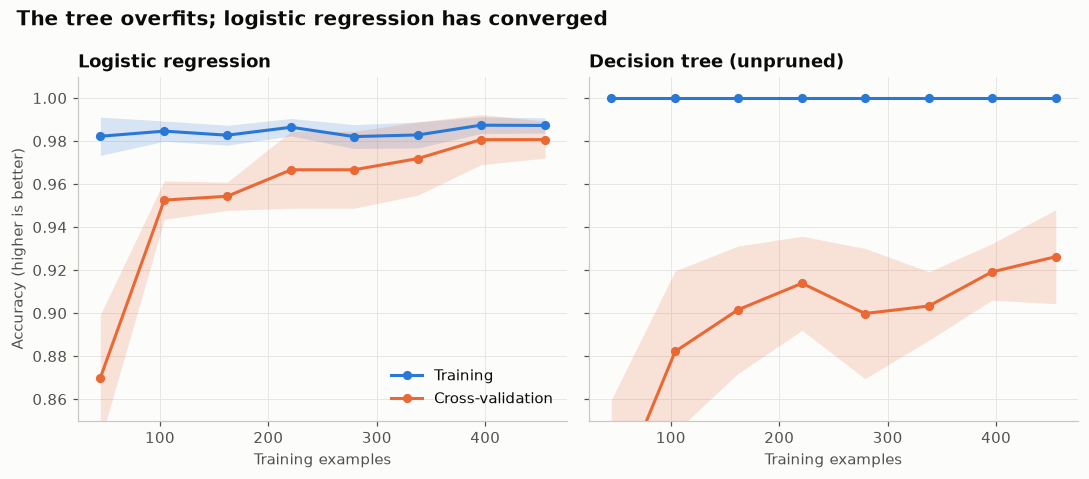

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, (name, (sizes, tr, va)) in zip(axes, curves.items()):
    for scores, color, label in [(tr, PALETTE[0], "Training"), (va, PALETTE[1], "Cross-validation")]:
        mu, sd = scores.mean(axis=1), scores.std(axis=1)
        ax.fill_between(sizes, mu - sd, mu + sd, color=color, alpha=0.18, linewidth=0)
        ax.plot(sizes, mu, color=color, marker="o", markersize=5, label=label)
    ax.set_title(name, fontsize=11.5)
    ax.set_xlabel("Training examples")
axes[0].set_ylabel("Accuracy (higher is better)")
axes[0].set_ylim(0.85, 1.01)
axes[0].legend(loc="lower right")
fig.suptitle("The tree overfits; logistic regression has converged",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

For the logistic regression (left) the two curves converge near 98%, so more data would help little. The decision tree (right) scores 100% on its training data while validation stays lower, a persistent gap that signals overfitting.

---
Standalone script: [`learning_curve.py`](learning_curve.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)